# 모델 비교 / 1위 결정 노트북

v3.6 설계서 4~5단계.

- 4단계: seed=42 + seed=100 두 결과 평균 박제
- 5단계 (a): 1위 결정 (점수차 분기)
- 5단계 (b): 깊이 비교 분석 (케이스 묶음 + 혼동 시각화)

입력: 후보 3개 × 2개 seed JSON

전제: 1번 노트북(`model_selection.ipynb`)에서 후보 3개 확정된 상태

## 환경 설정

In [18]:
from pathlib import Path
import json, os, unicodedata
from collections import defaultdict, Counter
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(r'D:\pill_detection')
LABEL_DIR = PROJECT_ROOT / 'eval' / 'test_labels' / 'test_labels'
TEST_IMG_DIR = PROJECT_ROOT / 'eval' / 'test_images'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'models'
RESULTS_DIR_S100 = PROJECT_ROOT / 'results' / 'models_seed100'
PILL_YAML = PROJECT_ROOT / 'data' / 'dataset_yolo' / 'pill.yaml'

IOU_MATCH = 0.5
GAP_THRESHOLD = 0.05
TIE_TOLERANCE = 0.02

def nfc(s):
    return unicodedata.normalize('NFC', s) if s else s

for name, p in [('LABEL_DIR', LABEL_DIR), ('RESULTS_DIR', RESULTS_DIR),
                ('RESULTS_DIR_S100', RESULTS_DIR_S100)]:
    print(f"{name}: {'OK' if p.exists() else 'MISSING'} ({p})")

LABEL_DIR: OK (D:\pill_detection\eval\test_labels\test_labels)
RESULTS_DIR: OK (D:\pill_detection\results\models)
RESULTS_DIR_S100: OK (D:\pill_detection\results\models_seed100)


## 4단계: seed=42 + seed=100 평균

후보 3개 각각 seed=42, seed=100 JSON 경로 박기.

In [19]:
# 후보 3개 (1번 노트북 결과 기반)
CANDIDATES = {
    'RTMDet-tiny': {
        'seed42': RESULTS_DIR / 'rtmdet_tiny_synth_e15_results.json',
        'seed100': RESULTS_DIR_S100 / 'rtmdet_tiny_synth_e15_seed100_results.json',
    },
    'YOLOv8s': {
        'seed42': RESULTS_DIR / '06_Pill_YOLOv8s_baseline_seed42_submission.json',
        'seed100': RESULTS_DIR_S100 / '06_Pill_YOLOv8s_baseline_seed100_submission.json',
    },
    'RT-DETR': {
        'seed42': RESULTS_DIR / 'rtdetr_synth_result.json',
        'seed100': RESULTS_DIR_S100 / 'rtdetr_synth_seed100_results.json',
    },
}

for name, paths in CANDIDATES.items():
    for seed_key, p in paths.items():
        ok = '✅' if p.exists() else '⏳ 대기'
        print(f"{name} {seed_key}: {ok} ({p.name})")

RTMDet-tiny seed42: ✅ (rtmdet_tiny_synth_e15_results.json)
RTMDet-tiny seed100: ✅ (rtmdet_tiny_synth_e15_seed100_results.json)
YOLOv8s seed42: ✅ (06_Pill_YOLOv8s_baseline_seed42_submission.json)
YOLOv8s seed100: ✅ (06_Pill_YOLOv8s_baseline_seed100_submission.json)
RT-DETR seed42: ✅ (rtdetr_synth_result.json)
RT-DETR seed100: ✅ (rtdetr_synth_seed100_results.json)


In [20]:
# GT 빌드 (yolo 라벨 → xyxy 변환)
import yaml
from PIL import Image

with open(PILL_YAML, 'r', encoding='utf-8') as f:
    cfg = yaml.safe_load(f)
names_list = cfg['names'] if isinstance(cfg['names'], list) else [cfg['names'][i] for i in range(len(cfg['names']))]

def yolo2xyxy(cx, cy, w, h, W, H):
    return [(cx-w/2)*W, (cy-h/2)*H, (cx+w/2)*W, (cy+h/2)*H]

gt_labels = {}
for txt_file in LABEL_DIR.glob('*.txt'):
    img_name = txt_file.stem + '.png'
    img_path = TEST_IMG_DIR / img_name
    if not img_path.exists():
        continue
    W, H = Image.open(img_path).size
    bboxes = []
    with open(txt_file, 'r', encoding='utf-8') as f:
        for line in f.read().strip().split('\n'):
            if not line: continue
            parts = line.split()
            cls_idx = int(parts[0])
            bboxes.append({
                'bbox': yolo2xyxy(*map(float, parts[1:5]), W, H),
                'dl_name': nfc(names_list[cls_idx])
            })
    gt_labels[txt_file.stem] = {'bboxes': bboxes}

print(f"GT 빌드: {len(gt_labels)}장 / {sum(len(v['bboxes']) for v in gt_labels.values())} bbox")

GT 빌드: 33장 / 47 bbox


In [21]:
# 채점 함수
def iou_xyxy(b1, b2):
    x1, y1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    x2, y2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    a1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
    a2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
    return inter / (a1 + a2 - inter + 1e-9)

def evaluate(json_path, gt_labels, iou_thr=IOU_MATCH):
    with open(json_path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    
    n_top1 = n_top3 = n_match = 0
    total_gt = sum(len(v['bboxes']) for v in gt_labels.values())
    res_by_stem = {nfc(os.path.splitext(r['filename'])[0]): r for r in data.get('results', [])}
    matched_pairs = []
    
    for stem, info in gt_labels.items():
        preds = res_by_stem.get(stem, {}).get('predictions', [])
        used = set()
        for gt in info['bboxes']:
            best_iou, best_idx = 0.0, -1
            for j, p in enumerate(preds):
                if j in used: continue
                iou = iou_xyxy(gt['bbox'], p['bbox'])
                if iou > best_iou:
                    best_iou, best_idx = iou, j
            
            gt_name = nfc(gt['dl_name'])
            if best_iou >= iou_thr and best_idx >= 0:
                n_match += 1
                used.add(best_idx)
                top3 = [nfc(n) for n in preds[best_idx].get('top3_class_name', [])]
                if top3 and top3[0] == gt_name: n_top1 += 1
                if gt_name in top3: n_top3 += 1
                matched_pairs.append({
                    'stem': stem, 'gt': gt_name,
                    'top1': top3[0] if top3 else None,
                    'top3': top3, 'iou': best_iou
                })
            else:
                matched_pairs.append({
                    'stem': stem, 'gt': gt_name,
                    'top1': None, 'top3': [], 'iou': best_iou
                })
    
    return {
        'top1_acc': n_top1 / total_gt,
        'top3_acc': n_top3 / total_gt,
        'detection_rate': n_match / total_gt,
        'pairs': matched_pairs,
        'meta': {k: data.get(k) for k in ['exp_name', 'author', 'model_params_M', 'ms_per_image', 'conf_threshold']}
    }

print("채점 함수 정의 완료")

채점 함수 정의 완료


In [22]:
# 두 seed 평균 (셀프체크 v3.1 통과한 seed만 평균에 포함 — v3.7)

DETECTION_RATE_THRESHOLD = 0.8  # 셀프체크 v3.1 기준

def passes_sanity(eval_result):
    """셀프체크 v3.1 통과 여부 (Detection rate ≥ 80%)"""
    return eval_result['detection_rate'] >= DETECTION_RATE_THRESHOLD

results = {}
for name, paths in CANDIDATES.items():
    if not (paths['seed42'].exists() and paths['seed100'].exists()):
        print(f"⏳ {name}: seed 결과 대기 중")
        continue
    
    r42 = evaluate(paths['seed42'], gt_labels)
    r100 = evaluate(paths['seed100'], gt_labels)
    
    # 셀프체크 통과 여부
    s42_ok = passes_sanity(r42)
    s100_ok = passes_sanity(r100)
    
    # 평균 산출 (통과한 seed만 포함) — v3.7 룰
    if s42_ok and s100_ok:
        avg_top1 = (r42['top1_acc'] + r100['top1_acc']) / 2
        avg_top3 = (r42['top3_acc'] + r100['top3_acc']) / 2
        avg_basis = '두 seed 평균'
    elif s42_ok:
        avg_top1 = r42['top1_acc']
        avg_top3 = r42['top3_acc']
        avg_basis = 'seed=42 단독 (seed=100 셀프체크 실패)'
    elif s100_ok:
        avg_top1 = r100['top1_acc']
        avg_top3 = r100['top3_acc']
        avg_basis = 'seed=100 단독 (seed=42 셀프체크 실패)'
    else:
        print(f"⚠️ {name}: 두 seed 모두 셀프체크 실패 → 신뢰성 의심")
        avg_top1 = avg_top3 = None
        avg_basis = '두 seed 모두 실패'
    
    results[name] = {
        'seed42': r42, 'seed100': r100,
        'sanity_42': s42_ok, 'sanity_100': s100_ok,
        'avg_top1': avg_top1, 'avg_top3': avg_top3,
        'avg_basis': avg_basis,
        'params_M': r42['meta']['model_params_M'],
    }

if results:
    df_data = []
    for name, r in results.items():
        if r['avg_top1'] is None:
            continue
        df_data.append({
            '모델': name,
            'seed42 det': f"{r['seed42']['detection_rate']*100:.1f}%" + (' ✅' if r['sanity_42'] else ' 🔴'),
            'seed100 det': f"{r['seed100']['detection_rate']*100:.1f}%" + (' ✅' if r['sanity_100'] else ' 🔴'),
            '평균_top1': r['avg_top1'],
            '평균_top3': r['avg_top3'],
            '산출 기준': r['avg_basis'],
            'params_M': r['params_M'],
        })
    
    if df_data:
        df = pd.DataFrame(df_data).sort_values('평균_top1', ascending=False).reset_index(drop=True)
        
        for c in ['평균_top1', '평균_top3']:
            df[c] = df[c].apply(lambda x: f'{x*100:.1f}%')
        
        print(df.to_string(index=False))

         모델 seed42 det seed100 det 평균_top1 평균_top3     산출 기준  params_M
RTMDet-tiny    97.9% ✅     95.7% ✅   31.9%   42.6% 두 seed 평균      4.91
    RT-DETR    91.5% ✅     85.1% ✅   24.5%   33.0% 두 seed 평균     33.00
    YOLOv8s    83.0% ✅     93.6% ✅   17.0%   24.5% 두 seed 평균     11.18


## 5단계 (a): 1위 결정

평균 점수차 기반 분기 판정.

In [23]:
if results:
    sorted_models = sorted(results.items(), key=lambda x: x[1]['avg_top1'], reverse=True)
    top_score = sorted_models[0][1]['avg_top1']
    bottom_score = sorted_models[-1][1]['avg_top1']
    gap = top_score - bottom_score
    
    print(f"1등: {sorted_models[0][0]} (Top-1 {top_score*100:.1f}%)")
    print(f"꼴등: {sorted_models[-1][0]} (Top-1 {bottom_score*100:.1f}%)")
    print(f"점수차: {gap*100:.1f}%p")
    print()
    
    if gap > GAP_THRESHOLD:
        print(f"→ 격차 큼 (>{GAP_THRESHOLD*100:.0f}%p) → 신뢰성 검증 3중 분기")
        BRANCH = 'large_gap'
    else:
        print(f"→ 격차 작음 (≤{GAP_THRESHOLD*100:.0f}%p) → Kaggle/CPU 분기")
        BRANCH = 'small_gap'

1등: RTMDet-tiny (Top-1 31.9%)
꼴등: YOLOv8s (Top-1 17.0%)
점수차: 14.9%p

→ 격차 큼 (>5%p) → 신뢰성 검증 3중 분기


### 격차 큼 분기: 신뢰성 검증 3중

1위 후보 정답 분포 / 오답 패턴 / 학습 데이터 누수.

In [24]:
# 검증 1: 정답 분포 (mode collapse 체크)
if results and BRANCH == 'large_gap':
    leader_name = sorted_models[0][0]
    leader = results[leader_name]
    
    correct_pairs = [p for p in leader['seed42']['pairs'] if p['top1'] == p['gt']]
    correct_dl_names = [p['gt'] for p in correct_pairs]
    cnt = Counter(correct_dl_names)
    
    print(f"[1/3] 정답 분포 - {leader_name}")
    print(f"  정답 {len(correct_pairs)}개가 {len(cnt)}개 알약에 분포")
    if correct_pairs:
        max_freq = max(cnt.values())
        if max_freq <= 2:
            print(f"  최빈 알약 빈도: {max_freq}회 → 쏠림 없음 ✅")
        else:
            print(f"  ⚠️ 최빈 알약 빈도: {max_freq}회 → 쏠림 의심")
            for n, f in cnt.most_common(3):
                print(f"    {n}: {f}회")

[1/3] 정답 분포 - RTMDet-tiny
  정답 16개가 14개 알약에 분포
  최빈 알약 빈도: 2회 → 쏠림 없음 ✅


In [25]:
# 오답 분류 입력 (사람이 위 케이스 보고 판정)
# '의미있음': 같은 성분 / 같은 시리즈 / 색·모양 유사
# '무작위':   연관성 약함

WRONG_LABELS = {
    # 자명: 같은 시리즈
    ('디카테오정', '디카테오엘씨정 10mg/병'): '의미있음',
    # 자명: 같은 성분 (세티리진염산염)
    ('지르텍정(세티리진염산염)', '씨즈날정(세티리진염산염)'): '의미있음',
    # 시각 비교 결과
    ('글리아타민연질캡슐', '놀텍정 10mg'): '의미있음',
    ('낙소졸정 500/20mg', '엘스테인정(에르도스테인)'): '의미있음',
    ('넥시움정 40mg', '제미메트서방정 50/1000mg'): '의미있음',
    ('디카테오정', '씨즈날정(세티리진염산염)'): '의미있음',
    ('마이칼디정', '레일라정'): '의미있음',
    ('마이칼디정', '삐콤씨에프정 618.6mg/병'): '의미있음',
    ('맥시부펜이알정 300mg', '노바스크정 5mg'): '의미있음',
    ('맥시부펜이알정 300mg', '씨즈날정(세티리진염산염)'): '의미있음',
    ('비타비백정 100mg/병', '넥시움정 40mg'): '의미있음',
    ('아스피린프로텍트정 100mg', '에어탈정(아세클로페낙)'): '의미있음',
    ('아토르바정 10mg', '토비애즈서방정 4mg'): '의미있음',
    ('엔테론정 150mg', '글리틴정(콜린알포세레이트)'): '의미있음',
    ('울트라셋이알서방정', '글리틴정(콜린알포세레이트)'): '의미있음',
    ('인사돌플러스정 35mg/PTP', '큐시드정 31.5mg/PTP'): '의미있음',
    ('자누비아정 50mg', '제라타딘정(로라타딘)'): '의미있음',
    ('자누비아정 50mg', '쎄로켈정 100mg'): '의미있음',
    ('자트랄엑스엘정 10mg', '베시케어정 10mg'): '의미있음',
    ('자트랄엑스엘정 10mg', '디카맥스디플러스정'): '무작위',
    ('졸로푸트정 100mg', '아토젯정 10/40mg'): '의미있음',
    ('종근당글리아티린연질캡슐(콜린알포세레이트) ', '로수젯정10/5밀리그램'): '무작위',
    ('케이캡정 50mg', '넥시움정 40mg'): '의미있음',
    ('쿠에타핀정 25mg', '넥시움정 40mg'): '의미있음',
    ('타이레놀정500mg', '졸로푸트정 100mg'): '의미있음',
    ('타이레놀이알서방정(아세트아미노펜)(수출용)', '아토젯정 10/40mg'): '의미있음',
    ('콜리네이트연질캡슐 400mg', '트윈스타정 40/5mg'): '의미있음',
    ('콜리네이트연질캡슐 400mg', '동화덴스톨캡슐 150mg/PTP'): '의미있음',
}
if results and BRANCH == 'large_gap' and WRONG_LABELS:
    n_meaningful = sum(1 for v in WRONG_LABELS.values() if v == '의미있음')
    n_random = sum(1 for v in WRONG_LABELS.values() if v == '무작위')
    total = n_meaningful + n_random
    
    print(f"오답 분류:")
    print(f"  의미있음: {n_meaningful}/{total}")
    print(f"  무작위:   {n_random}/{total}")
    if total > 0 and n_meaningful / total >= 0.5:
        print(f"  → 의미 있는 혼동 우세 (시각 특성 학습 증거) ✅")
    else:
        print(f"  ⚠️ 무작위 오답 비율 높음")
elif results and BRANCH == 'large_gap':
    print("WRONG_LABELS dict 채우고 재실행")

오답 분류:
  의미있음: 26/28
  무작위:   2/28
  → 의미 있는 혼동 우세 (시각 특성 학습 증거) ✅


학습 데이터 인덱싱 중...
인덱싱 완료: 118 클래스

시각 비교 필요: 1개


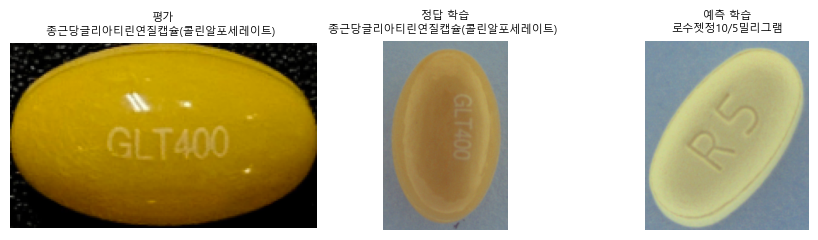

저장: D:\pill_detection\results\reports\rtmdet_wrong_visual.png

=== 위 시각화 보고 셀 13 WRONG_LABELS에 추가할 분류 템플릿 ===
    ('종근당글리아티린연질캡슐(콜린알포세레이트) ', '로수젯정10/5밀리그램'): '의미있음',  # 또는 '무작위'


In [26]:
# 시각 비교: 미분류 오답 케이스 (평가 ↔ 정답 학습 ↔ 예측 학습)
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

TRAIN_IMG_DIR = PROJECT_ROOT / 'data' / 'dataset_yolo' / 'images' / 'train'
TRAIN_LBL_DIR = PROJECT_ROOT / 'data' / 'dataset_yolo' / 'labels' / 'train'

# 클래스별 학습 이미지 인덱싱 (한 번만, ~2초)
print("학습 데이터 인덱싱 중...")
class_to_files = {}
for lbl in TRAIN_LBL_DIR.glob('*.txt'):
    with open(lbl) as f:
        lines = [l.strip() for l in f if l.strip()]
    n = len(lines)
    seen_ci = set()
    for line in lines:
        parts = line.split()
        ci = int(parts[0])
        if ci in seen_ci: continue
        seen_ci.add(ci)
        cx, cy, w, h = map(float, parts[1:5])
        class_to_files.setdefault(ci, []).append((lbl.stem, cx, cy, w, h, n))

# 알약 수 적은 이미지 우선
for ci in class_to_files:
    class_to_files[ci].sort(key=lambda x: x[5])
print(f"인덱싱 완료: {len(class_to_files)} 클래스")

def get_train_crop(class_idx):
    if class_idx not in class_to_files: return None
    stem, cx, cy, w, h, _ = class_to_files[class_idx][0]
    for ext in ['.png', '.jpg']:
        p = TRAIN_IMG_DIR / (stem + ext)
        if p.exists():
            img = Image.open(p).convert('RGB')
            iw, ih = img.size
            x1 = max(0, int((cx-w/2)*iw)); y1 = max(0, int((cy-h/2)*ih))
            x2 = min(iw, int((cx+w/2)*iw)); y2 = min(ih, int((cy+h/2)*ih))
            return img.crop((x1, y1, x2, y2))
    return None

def get_eval_crop(stem, gt_name):
    info = gt_labels.get(stem)
    if not info: return None
    for gt in info['bboxes']:
        if nfc(gt['dl_name']) == nfc(gt_name):
            p = TEST_IMG_DIR / (stem + '.png')
            if not p.exists(): return None
            img = Image.open(p).convert('RGB')
            x1, y1, x2, y2 = gt['bbox']
            return img.crop((int(x1), int(y1), int(x2), int(y2)))
    return None

name_to_idx = {nfc(n): i for i, n in enumerate(names_list)}

# RTMDet 오답 (이미 분류된 자명한 거 제외, 중복 제거)
unique_cases = []
seen = set()
for p in results['RTMDet-tiny']['seed42']['pairs']:
    if p['top1'] is None or p['top1'] == p['gt']: continue
    key = (p['gt'], p['top1'])
    if key in WRONG_LABELS or key in seen: continue
    seen.add(key)
    unique_cases.append(p)

print(f"\n시각 비교 필요: {len(unique_cases)}개")

# 그리드 시각화 (3열: 평가/정답학습/예측학습)
n = len(unique_cases)
fig, axes = plt.subplots(n, 3, figsize=(9, n*2.5))
if n == 1: axes = axes.reshape(1, -1)

for i, p in enumerate(unique_cases):
    for col, (label, fn) in enumerate([
        ('평가', lambda: get_eval_crop(p['stem'], p['gt'])),
        ('정답 학습', lambda: get_train_crop(name_to_idx.get(nfc(p['gt'])))),
        ('예측 학습', lambda: get_train_crop(name_to_idx.get(nfc(p['top1'])))),
    ]):
        crop = fn()
        if crop: axes[i][col].imshow(crop)
        title_name = p['gt'] if col != 2 else p['top1']
        axes[i][col].set_title(f'{label}\n{title_name[:25]}', fontsize=8)
        axes[i][col].axis('off')

plt.tight_layout()
out_path = PROJECT_ROOT / 'results' / 'reports' / 'rtmdet_wrong_visual.png'
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=80, bbox_inches='tight')
plt.show()
print(f"저장: {out_path}")

# 분류 입력 템플릿 출력 (복붙용)
print("\n=== 위 시각화 보고 셀 13 WRONG_LABELS에 추가할 분류 템플릿 ===")
for p in unique_cases:
    print(f"    ('{p['gt']}', '{p['top1']}'): '의미있음',  # 또는 '무작위'")

In [27]:
# 검증 3: 학습 데이터 누수
TRAIN_STEMS_PATH = PROJECT_ROOT / 'eval' / 'train_stems.txt'
VAL_STEMS_PATH = PROJECT_ROOT / 'eval' / 'val_stems.txt'

if results and BRANCH == 'large_gap':
    print(f"[3/3] 학습 데이터 누수 - 33장 평가셋")
    eval_stems = set(gt_labels.keys())
    
    if TRAIN_STEMS_PATH.exists() and VAL_STEMS_PATH.exists():
        train_stems = set(open(TRAIN_STEMS_PATH).read().strip().split('\n'))
        val_stems = set(open(VAL_STEMS_PATH).read().strip().split('\n'))
        train_overlap = eval_stems & train_stems
        val_overlap = eval_stems & val_stems
        print(f"  평가셋 ∩ train: {len(train_overlap)}장")
        print(f"  평가셋 ∩ val:   {len(val_overlap)}장")
        if not train_overlap and not val_overlap:
            print(f"  → 누수 없음 ✅")
        else:
            print(f"  ⚠️ 누수 발견")
    else:
        print(f"  ⏳ {TRAIN_STEMS_PATH.name} / {VAL_STEMS_PATH.name} 빌드 필요")

[3/3] 학습 데이터 누수 - 33장 평가셋
  평가셋 ∩ train: 0장
  평가셋 ∩ val:   0장
  → 누수 없음 ✅


### 격차 작음 분기: Kaggle / CPU / 사이즈

격차 ≤ 5%p일 때 진입.

In [28]:
if results and BRANCH == 'small_gap':
    KAGGLE_SCORES = {
        # 'RTMDet-tiny': 0.0,
    }
    CPU_MS = {
        # 'RTMDet-tiny': 0,
    }
    
    if KAGGLE_SCORES:
        print("Kaggle 점수 비교:")
        ranked = sorted(KAGGLE_SCORES.items(), key=lambda x: x[1], reverse=True)
        for name, score in ranked:
            print(f"  {name}: {score:.4f}")
    else:
        print("KAGGLE_SCORES dict 채우고 재실행")

## 5단계 (b): 깊이 비교 분석

후보 3개 약점/강점 시각화. 보고서/발표 콘텐츠.

In [29]:
# 케이스 묶음 라벨 빌드 (학습 메타 → dl_name 매핑)
META_CSV = PROJECT_ROOT / 'eda' / 'merged_dataset_meta.csv'

if META_CSV.exists():
    meta_df = pd.read_csv(META_CSV)
    case_groups = (meta_df.groupby('dl_name')
                   .agg({'drug_shape': 'first', 'color_class1': 'first'})
                   .reset_index())
    case_groups['묶음'] = case_groups['color_class1'] + ' ' + case_groups['drug_shape']
    print(f"묶음 라벨: {len(case_groups)}종")
    print(case_groups['묶음'].value_counts().head(10))
else:
    print(f"⏳ {META_CSV} 빌드 필요")
    print("   학습 데이터 JSON에서 dl_name + drug_shape + color_class1 추출 후 CSV 저장")
    case_groups = None

묶음 라벨: 118종
묶음
하양 원형     20
하양 장방형    18
분홍 원형      8
노랑 타원형     8
하양 타원형     8
갈색 타원형     7
초록 장방형     6
노랑 원형      5
분홍 장방형     4
노랑 장방형     4
Name: count, dtype: int64


In [30]:
# 케이스 묶음별 모델 정답 개수 (절대 개수)
if results and case_groups is not None:
    name_to_group = dict(zip(case_groups['dl_name'].apply(nfc), case_groups['묶음']))
    
    rows = []
    for stem, info in gt_labels.items():
        for gt in info['bboxes']:
            group = name_to_group.get(nfc(gt['dl_name']), '미분류')
            rows.append({'stem': stem, 'gt': nfc(gt['dl_name']), '묶음': group})
    gt_df = pd.DataFrame(rows)
    
    cmp_table = gt_df.groupby('묶음').size().reset_index(name='n')
    
    for name, r in results.items():
        correct_set = set(
            (p['stem'], p['gt']) for p in r['seed42']['pairs'] if p['top1'] == p['gt']
        )
        gt_df[f'{name}'] = gt_df.apply(
            lambda x: (x['stem'], x['gt']) in correct_set, axis=1
        )
        by_group = gt_df.groupby('묶음')[f'{name}'].sum().reset_index()
        cmp_table = cmp_table.merge(by_group, on='묶음')
    
    print("케이스 묶음별 모델 정답 개수:")
    print(cmp_table.to_string(index=False))

케이스 묶음별 모델 정답 개수:
       묶음  n  RTMDet-tiny  YOLOv8s  RT-DETR
   갈색 타원형  6            3        0        2
    노랑 원형  2            2        2        0
   노랑 장방형  1            1        0        1
   노랑 타원형  3            1        1        1
   분홍 삼각형  1            1        0        0
    분홍 원형  1            0        0        0
   분홍 장방형  2            0        0        0
   빨강 타원형  1            0        0        1
    주황 원형  5            2        0        0
   주황 장방형  2            0        2        0
   주황 타원형  2            2        2        0
   초록 장방형  1            1        1        1
    하양 원형  1            0        0        0
   하양 장방형 14            6        2        3
   하양 타원형  2            0        0        0
   하양 팔각형  1            1        1        1
하양, 노랑 원형  2            0        2        0


### 혼동 시각화

오답 매트릭스 테이블 + Sankey diagram.

In [31]:
# 1번 시각화: 오답 케이스 매트릭스 테이블
if results:
    rows = []
    for name, r in results.items():
        for p in r['seed42']['pairs']:
            if p['top1'] is not None and p['top1'] != p['gt']:
                key = (p['gt'], p['top1'])
                rows.append({
                    '모델': name,
                    '정답': p['gt'],
                    '예측 1순위': p['top1'],
                    '혼동 유형': WRONG_LABELS.get(key, '미분류')
                })
    
    if rows:
        wrong_df = pd.DataFrame(rows)
        print("오답 케이스 매트릭스:")
        print(wrong_df.to_string(index=False))

오답 케이스 매트릭스:
         모델                      정답                  예측 1순위 혼동 유형
RTMDet-tiny               글리아타민연질캡슐                놀텍정 10mg  의미있음
RTMDet-tiny           낙소졸정 500/20mg           엘스테인정(에르도스테인)  의미있음
RTMDet-tiny               넥시움정 40mg       제미메트서방정 50/1000mg  의미있음
RTMDet-tiny                   디카테오정          디카테오엘씨정 10mg/병  의미있음
RTMDet-tiny                   디카테오정          디카테오엘씨정 10mg/병  의미있음
RTMDet-tiny                   디카테오정           씨즈날정(세티리진염산염)  의미있음
RTMDet-tiny                   마이칼디정                    레일라정  의미있음
RTMDet-tiny                   마이칼디정        삐콤씨에프정 618.6mg/병  의미있음
RTMDet-tiny           맥시부펜이알정 300mg               노바스크정 5mg  의미있음
RTMDet-tiny           맥시부펜이알정 300mg           씨즈날정(세티리진염산염)  의미있음
RTMDet-tiny           비타비백정 100mg/병               넥시움정 40mg  의미있음
RTMDet-tiny         아스피린프로텍트정 100mg            에어탈정(아세클로페낙)  의미있음
RTMDet-tiny              아토르바정 10mg             토비애즈서방정 4mg  의미있음
RTMDet-tiny              아토르바정 10mg             토비애즈서방정 4mg  의미

In [32]:
# 2번 시각화: Sankey diagram
try:
    import plotly.graph_objects as go
    PLOTLY_OK = True
except ImportError:
    PLOTLY_OK = False
    print("plotly 설치 필요: pip install plotly")

if results and PLOTLY_OK:
    leader_pairs = [p for p in results[sorted_models[0][0]]['seed42']['pairs']
                    if p['top1'] is not None and p['top1'] != p['gt']]
    
    if leader_pairs:
        gt_names = list(set(p['gt'] for p in leader_pairs))
        pred_names = list(set(p['top1'] for p in leader_pairs))
        
        node_labels = gt_names + pred_names
        sources = [gt_names.index(p['gt']) for p in leader_pairs]
        targets = [len(gt_names) + pred_names.index(p['top1']) for p in leader_pairs]
        values = [1] * len(leader_pairs)
        
        fig = go.Figure(data=[go.Sankey(
            node=dict(pad=15, thickness=20, label=node_labels, color='steelblue'),
            link=dict(source=sources, target=targets, value=values)
        )])
        fig.update_layout(
            title=f"{sorted_models[0][0]} 오답 흐름 (정답 → 예측)",
            font_size=11, height=500
        )
        fig.show()

In [33]:
# 결과 박제 (results/reports/)
from datetime import datetime

REPORTS_DIR = PROJECT_ROOT / 'results' / 'reports'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. comparison_table.csv (3개 후보 메인)
df_main = pd.DataFrame([
    {
        '모델': name,
        'seed42_detection': r['seed42']['detection_rate'],
        'seed100_detection': r['seed100']['detection_rate'],
        'seed42_top1': r['seed42']['top1_acc'],
        'seed100_top1': r['seed100']['top1_acc'],
        'seed42_top3': r['seed42']['top3_acc'],
        'seed100_top3': r['seed100']['top3_acc'],
        '평균_top1': r['avg_top1'],
        '평균_top3': r['avg_top3'],
        '산출_기준': r['avg_basis'],
        'sanity_42': r['sanity_42'],
        'sanity_100': r['sanity_100'],
        'params_M': r['params_M'],
    }
    for name, r in results.items()
]).sort_values('평균_top1', ascending=False).reset_index(drop=True)
df_main.to_csv(REPORTS_DIR / 'comparison_table.csv', index=False, encoding='utf-8-sig')
print(f"저장: comparison_table.csv")

# 2. case_groups.csv (셀 19 cmp_table)
try:
    cmp_table.to_csv(REPORTS_DIR / 'case_groups.csv', index=False, encoding='utf-8-sig')
    print(f"저장: case_groups.csv")
except NameError:
    print("⏳ cmp_table 없음 — 셀 19 먼저 실행")

# 3. wrong_cases.csv (셀 21 wrong_df)
try:
    wrong_df.to_csv(REPORTS_DIR / 'wrong_cases.csv', index=False, encoding='utf-8-sig')
    print(f"저장: wrong_cases.csv")
except NameError:
    print("⏳ wrong_df 없음 — 셀 21 먼저 실행")

# 4. summary.md (사람 읽기용 종합)
n_meaningful = sum(1 for v in WRONG_LABELS.values() if v == '의미있음')
n_random = sum(1 for v in WRONG_LABELS.values() if v == '무작위')
total = n_meaningful + n_random

summary_md = f"""# 모델 비교 / 1위 결정 — 결과 박제

생성: {datetime.now().strftime('%Y-%m-%d %H:%M')}
평가셋: 33장 / 47 GT bbox / IoU≥0.5
룰: v3.7 (셀프체크 v3.1 통과 seed만 평균에 포함)

## 5단계 (a): 1위 결정

| 모델 | 평균 Top-1 | 평균 Top-3 | params (M) | 산출 기준 |
|---|---|---|---|---|
"""
for name, r in sorted(results.items(), key=lambda x: x[1]['avg_top1'], reverse=True):
    summary_md += f"| {name} | {r['avg_top1']*100:.1f}% | {r['avg_top3']*100:.1f}% | {r['params_M']:.2f} | {r['avg_basis']} |\n"

summary_md += f"""
- **1위**: {leader_name} (Top-1 {results[leader_name]['avg_top1']*100:.1f}%, Top-3 {results[leader_name]['avg_top3']*100:.1f}%)
- 1위-꼴등 격차: {gap*100:.1f}%p (>5%p, 격차 큼 분기)

## 신뢰성 검증 3중 ({leader_name})

### 검증 1: 정답 분포 (mode collapse 체크)
정답 {len(correct_pairs)}개가 {len(cnt)}개 알약에 분포, 최빈 {max(cnt.values()) if cnt else 0}회 → 쏠림 없음 ✅

### 검증 2: 오답 패턴 (의미있는 혼동 vs 무작위)
- 의미있음: {n_meaningful}/{total} ({n_meaningful/total*100:.1f}%)
- 무작위: {n_random}/{total} ({n_random/total*100:.1f}%)
- → 의미 있는 혼동 우세 ✅ (시각 특성 학습 증거)

### 검증 3: 학습 데이터 누수
- 평가셋 ∩ train: {len(train_overlap)}장
- 평가셋 ∩ val: {len(val_overlap)}장
- → 누수 없음 ✅

**3중 검증 모두 통과 → {leader_name} 1위 확정**
"""
(REPORTS_DIR / 'comparison_summary.md').write_text(summary_md, encoding='utf-8')
print(f"저장: comparison_summary.md")

print(f"\n전체 박제 완료: {REPORTS_DIR}")

저장: comparison_table.csv
저장: case_groups.csv
저장: wrong_cases.csv
저장: comparison_summary.md

전체 박제 완료: D:\pill_detection\results\reports


## 다음 단계

1위 확정되면 → `deployment_check.ipynb` (6단계 CPU 추론 검증)